# Detector de los 5 discos lumbares (YOLOv8n, cajas) · Entrenamiento y evaluación

**Proyecto:** Visión Artificial 2026-A · **Modelo:** YOLOv8 nano (Ultralytics), detección con **cajas normales (sin OBB)** · **Clases:** L1-L2, L2-L3, L3-L4, L4-L5, L5-S1.

**Lugar en la aplicación:** corte con el segmento L1-S1 → **este modelo ubica los 5 discos** → `autocrop_rois.py` expande cada caja (mismos márgenes) y recorta el ROI de 128×128 → los 4 modelos clasifican cada ROI.

Este cuaderno **reentrena** el detector (la versión anterior se entrenó solo 50 épocas y no guardó métricas) y deja todo documentado en tu Drive.

### Cómo usarlo
1. Entorno de ejecución → **GPU** (T4 sirve).
2. En Colab, panel izquierdo → 🔑 **Secretos** → crea `ROBOFLOW_API_KEY` y activa *Acceso desde el cuaderno*. La clave nunca se escribe en el código.
3. Revisa workspace / proyecto / versión en la configuración (vienen del cuaderno anterior).
4. Ejecuta de arriba hacia abajo. Todo se guarda en Drive (sección 8).

### Qué mide
- **mAP50, mAP50-95, precisión y recall** (estándar de detección), globales y **por nivel**.
- **Métrica práctica**: el pipeline necesita **los 5 niveles, en orden y sin solaparse** (es la misma regla con la que se descartaron imágenes al construir el dataset). Se mide el porcentaje de cortes que cumplen eso con el umbral de uso (confianza 0.35, NMS 0.4, como `autocrop_rois.py`), y el IoU por nivel.
- El umbral de uso se calibra con **valid**; **test** (si el proyecto de Roboflow lo tiene) se mira una sola vez.

### Límites
- Dataset pequeño: unas decenas de cortes en valid. Un corte mueve los porcentajes varios puntos; no interpretes diferencias pequeñas.
- Si el proyecto de Roboflow **no tiene test**, `best.pt` se elige con valid y las métricas de valid salen algo infladas. El cuaderno lo avisa y omite lo que depende de test.
- Una sola corrida y una sola semilla. Si varios cortes de un mismo paciente quedan en particiones distintas, las métricas salen infladas (la sección 2 lo comprueba por el nombre del archivo).

## 0. Configuración (lo único que se edita)

In [ ]:
# ================== VARIABLES A RELLENAR ==================
RF_WORKSPACE = "datascience-3acw1"     # workspace de Roboflow (el del cuaderno anterior)
RF_PROJECT   = "intervertebral-disks"  # proyecto de detección de discos
RF_VERSION   = 1
SECRET_NAME  = "ROBOFLOW_API_KEY"      # nombre del secreto en Colab (no la clave)

MODELO_BASE = "yolov8n.pt"             # YOLOv8 nano preentrenado en COCO; cajas normales, sin OBB

# --- Hiperparámetros de entrenamiento ---
EPOCAS         = 50       # la versión anterior usó 50
PACIENCIA      = 30        # parada temprana: épocas sin mejorar fitness en valid
BATCH          = 16
IMGSZ          = 640
OPTIMIZADOR    = "auto"
LR0            = 0.01
LRF            = 0.01
WEIGHT_DECAY   = 0.0005
WARMUP_EPOCHS  = 3.0
COS_LR         = False
CLOSE_MOSAIC   = 10
SEMILLA        = 42

# Aumento en línea: valores por defecto de Ultralytics, escritos aquí para que queden registrados.
# (El volteo horizontal no cambia el nivel de un disco: el orden L1->S1 es vertical.)
AUG = dict(fliplr=0.5, flipud=0.0, degrees=0.0, translate=0.1, scale=0.5, shear=0.0,
           hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, mosaic=1.0, mixup=0.0)

# --- Uso en el pipeline (iguales a autocrop_rois.py) ---
CONF_USO     = 0.35   # confianza mínima; se calibra con valid en la sección 6
IOU_NMS_USO  = 0.40   # NMS usado en autocrop_rois.py
IOU_NMS_EVAL = 0.60   # NMS de la evaluación estándar (mAP)
MARGIN_POST, MARGIN_ANT, MARGIN_VERT, PATCH = 0.40, 0.10, 0.50, 128   # expansión del ROI y tamaño final

# Salidas en Google Drive
DRIVE_DIR = "/content/drive/MyDrive/VisionArtificial/detector_discos"
CONTINUAR_DESDE = None   # p. ej. ".../<run>/checkpoint/last.pt" para reanudar una corrida interrumpida
EXPORTAR_ONNX   = False
CARPETA_PRUEBAS = "/content/pruebas"   # opcional: PNG de un paciente para ver la detección (sección 7)
# ==========================================================

## 1. Instalación y entorno

In [ ]:
!pip -q install ultralytics roboflow

In [ ]:
import os, re, json, random, shutil, datetime, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2, yaml, torch, ultralytics

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
fijar_semilla(SEMILLA)

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO HAY GPU (activa una en Entorno de ejecución)")
print("ultralytics", ultralytics.__version__, "· torch", torch.__version__)

from google.colab import drive
drive.mount("/content/drive")
os.makedirs(DRIVE_DIR, exist_ok=True)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
GPU: Tesla T4
ultralytics 8.4.194 · torch 2.11.0+cu130
Mounted at /content/drive


## 2. Descarga del dataset desde Roboflow y revisión
La clave se lee de *Colab Secrets*; no queda en el cuaderno.

In [ ]:
from google.colab import userdata
from roboflow import Roboflow

try:
    api_key = userdata.get(SECRET_NAME)
except Exception as e:
    raise RuntimeError(f"No encuentro el secreto '{SECRET_NAME}'. Créalo en 🔑 Secretos y activa el acceso desde el cuaderno.") from e

rf = Roboflow(api_key=api_key)
version = rf.workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION)
dataset = version.download("yolov8", location="/content/dataset_rf")   # cajas normales
DATA = Path(dataset.location)
YAML = DATA / "data.yaml"
print("Dataset en:", DATA)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/dataset_rf in yolov8:: 100%|██████████| 205/205 [00:00<00:00, 9375.15it/s]

Dataset en: /content/dataset_rf


In [ ]:
cfg = yaml.safe_load(open(YAML, encoding="utf-8"))
NOMBRES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][k] for k in sorted(cfg["names"])]
NIVELES = list(NOMBRES)
print("Clases:", NIVELES)
assert len(NIVELES) == 5, f"Se esperaban 5 clases (un disco por nivel) y hay {len(NIVELES)}."

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
def carpeta_split(nombre, obligatorio=True):
    for cand in ([nombre, "valid"] if nombre == "val" else [nombre]):
        if (DATA / cand / "images").is_dir(): return DATA / cand
    if obligatorio: raise FileNotFoundError(f"No encuentro la partición '{nombre}' en {DATA}.")
    return None

SPLITS = {"train": carpeta_split("train"), "val": carpeta_split("val")}
_t = carpeta_split("test", obligatorio=False)
if _t is not None and any((_t / "images").iterdir()): SPLITS["test"] = _t
TIENE_TEST = "test" in SPLITS
if not TIENE_TEST:
    print("⚠ El proyecto NO tiene partición test: se evalúa solo en valid (best.pt se elige con valid, así que está algo inflado).")

def listar(split): return sorted(p for p in (SPLITS[split] / "images").iterdir() if p.suffix.lower() in IMG_EXT)
def etiqueta_de(p): return p.parent.parent / "labels" / (p.stem + ".txt")

IMGS = {s: listar(s) for s in SPLITS}
n_tot = sum(len(v) for v in IMGS.values())
filas = []
for s, v in IMGS.items():
    filas.append(dict(particion=s, imagenes=len(v), porcentaje=round(100 * len(v) / n_tot, 1)))
resumen_dataset = pd.DataFrame(filas); display(resumen_dataset)
assert all(len(v) > 0 for v in IMGS.values()), "Alguna partición está vacía."

Clases: ['L1-L2', 'L2-L3', 'L3-L4', 'L4-L5', 'L5-S1']


,particion,imagenes,porcentaje
0,train,70,70.0
1,val,20,20.0
2,test,10,10.0


In [ ]:
# Instancias por clase y partición (cada corte debería tener 1 disco por nivel)
def leer_etiquetas(p, w, h):
    """{clase_id: (x1,y1,x2,y2) en píxeles}; si hay varias del mismo nivel, la de mayor área."""
    f = etiqueta_de(p); out = {}
    if not f.exists(): return out
    for linea in f.read_text().strip().splitlines():
        v = linea.split()
        if len(v) < 5: continue
        c = int(float(v[0])); vals = [float(x) for x in v[1:]]
        if len(vals) == 4:
            cx, cy, bw, bh = vals; caja = ((cx - bw/2) * w, (cy - bh/2) * h, (cx + bw/2) * w, (cy + bh/2) * h)
        else:
            xs, ys = np.array(vals[0::2]) * w, np.array(vals[1::2]) * h; caja = (xs.min(), ys.min(), xs.max(), ys.max())
        a = (caja[2] - caja[0]) * (caja[3] - caja[1])
        if c not in out or a > (out[c][2] - out[c][0]) * (out[c][3] - out[c][1]): out[c] = caja
    return out

filas, cortes_incompletos = [], []
for s, v in IMGS.items():
    cuenta = {n: 0 for n in NIVELES}; tam = []
    for p in v:
        im = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if im is None: continue
        h, w = im.shape; g = leer_etiquetas(p, w, h)
        for c, caja in g.items():
            cuenta[NIVELES[c]] += 1; tam.append(((caja[2]-caja[0]) / w, (caja[3]-caja[1]) / h))
        if len(g) < 5: cortes_incompletos.append((s, p.name, len(g)))
    t = np.array(tam)
    filas.append(dict(particion=s, **cuenta, ancho_medio=round(t[:, 0].mean(), 3), alto_medio=round(t[:, 1].mean(), 3)))
display(pd.DataFrame(filas))
if cortes_incompletos:
    print(f"⚠ {len(cortes_incompletos)} cortes con menos de 5 niveles etiquetados (primeros 5):", cortes_incompletos[:5])
else:
    print("Todos los cortes tienen los 5 niveles etiquetados.")

,particion,L1-L2,L2-L3,L3-L4,L4-L5,L5-S1,ancho_medio,alto_medio
0,train,70,70,70,70,70,0.142,0.070
1,val,20,20,20,20,20,0.140,0.068
2,test,10,10,10,10,10,0.143,0.068


Todos los cortes tienen los 5 niveles etiquetados.


In [ ]:
# Posible fuga: el mismo corte (o el mismo paciente) en particiones distintas
def base_name(p): return re.sub(r"[._]rf[._][0-9a-f]+$", "", p.stem)
def paciente(p):
    m = re.search(r"__(\d{4})_", p.name)
    return m.group(1) if m else None

nombres_split = list(IMGS)
pares = [(a, b) for i, a in enumerate(nombres_split) for b in nombres_split[i+1:]]
bases = {s: {base_name(p) for p in v} for s, v in IMGS.items()}
for a, b in pares:
    comun = bases[a] & bases[b]
    print(f"Mismo corte en {a} y {b}: {len(comun)}" + ("  ⚠ FUGA" if comun else "  OK"))
pac = {s: {paciente(p) for p in v} - {None} for s, v in IMGS.items()}
if all(sum(paciente(p) is not None for p in v) / len(v) > 0.9 for v in IMGS.values()):
    for a, b in pares:
        comun = pac[a] & pac[b]
        print(f"Pacientes en {a} y {b}: {len(comun)}" + ("  ⚠ FUGA POR PACIENTE" if comun else "  OK"))
else:
    print("⚠ Los nombres no traen el número de paciente: no puedo comprobar si el split es por paciente.")

Mismo corte en train y val: 0  OK
Mismo corte en train y test: 0  OK
Mismo corte en val y test: 0  OK
Pacientes en train y val: 15  ⚠ FUGA POR PACIENTE
Pacientes en train y test: 7  ⚠ FUGA POR PACIENTE
Pacientes en val y test: 6  ⚠ FUGA POR PACIENTE


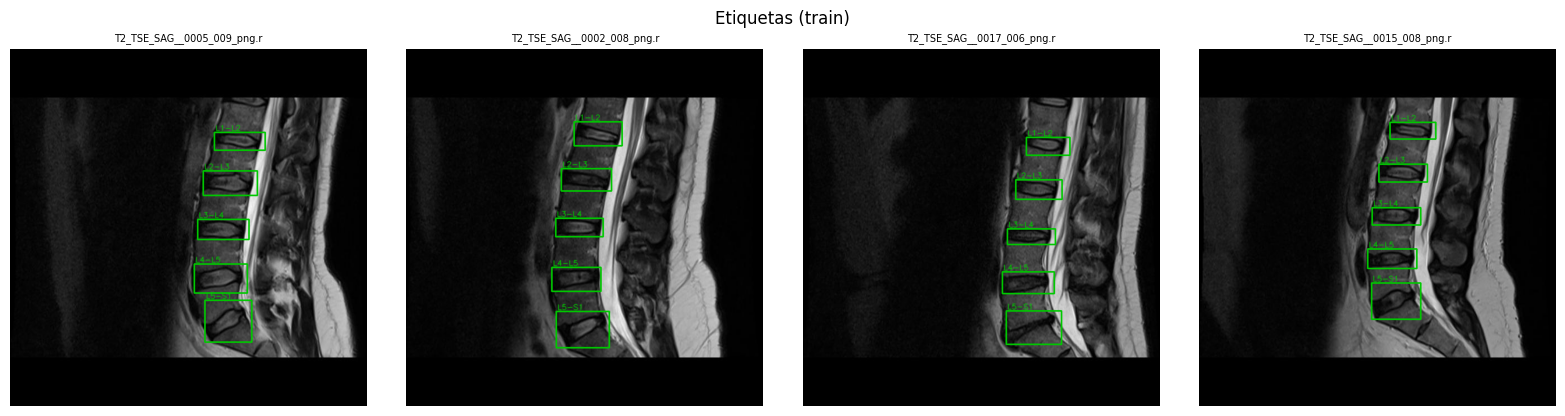

In [ ]:
# Ejemplos con las etiquetas
def dibujar(img_bgr, cajas, color, textos=None):
    for i, caja in enumerate(cajas):
        x1, y1, x2, y2 = map(int, caja); cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, 2)
        if textos: cv2.putText(img_bgr, textos[i], (x1 + 2, max(12, y1 - 3)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, color, 1, cv2.LINE_AA)
    return img_bgr

muestra = random.Random(SEMILLA).sample(IMGS["train"], min(4, len(IMGS["train"])))
fig, axs = plt.subplots(1, len(muestra), figsize=(4 * len(muestra), 4.2), squeeze=False)
for ax, p in zip(axs[0], muestra):
    im = cv2.cvtColor(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE), cv2.COLOR_GRAY2BGR); h, w = im.shape[:2]
    g = leer_etiquetas(p, w, h)
    ax.imshow(cv2.cvtColor(dibujar(im, [g[c] for c in sorted(g)], (0, 200, 0), [NIVELES[c] for c in sorted(g)]), cv2.COLOR_BGR2RGB))
    ax.set_title(p.name[:26], fontsize=7); ax.axis("off")
plt.suptitle("Etiquetas (train)"); plt.tight_layout(); plt.show()

## 3. Entrenamiento
Se guarda `last.pt` en tu Drive **al terminar cada época** (si se corta Colab, se reanuda con `CONTINUAR_DESDE`). Todos los hiperparámetros están en la configuración y Ultralytics los guarda también en `args.yaml`.

In [ ]:
from ultralytics import YOLO

RUN_NAME = "detector_discos_v%s_s%d_%s" % (RF_VERSION, SEMILLA, datetime.datetime.now().strftime("%Y%m%d_%H%M"))
RUNS = Path("/content/runs")
DEST = Path(DRIVE_DIR) / RUN_NAME
(DEST / "checkpoint").mkdir(parents=True, exist_ok=True)

def guardar_checkpoint(trainer):
    """Copia last.pt y results.csv a Drive tras cada época."""
    try:
        shutil.copy(trainer.last, DEST / "checkpoint" / "last.pt")
        rc = Path(trainer.save_dir) / "results.csv"
        if rc.exists(): shutil.copy(rc, DEST / "checkpoint" / "results.csv")
    except Exception as e:
        print("(aviso) no se pudo copiar el checkpoint a Drive:", e)

if CONTINUAR_DESDE:
    model = YOLO(CONTINUAR_DESDE)
    model.add_callback("on_model_save", guardar_checkpoint)
    resultados = model.train(resume=True)
    RUN_DIR = Path(model.trainer.save_dir)
else:
    model = YOLO(MODELO_BASE)
    model.add_callback("on_model_save", guardar_checkpoint)
    resultados = model.train(
        data=str(YAML), imgsz=IMGSZ, epochs=EPOCAS, patience=PACIENCIA, batch=BATCH,
        optimizer=OPTIMIZADOR, lr0=LR0, lrf=LRF, weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS,
        cos_lr=COS_LR, close_mosaic=CLOSE_MOSAIC,
        seed=SEMILLA, deterministic=True, workers=2,
        project=str(RUNS), name=RUN_NAME, exist_ok=True, plots=True,
        **AUG,
    )
    RUN_DIR = RUNS / RUN_NAME
print("Run en:", RUN_DIR)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_rf/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector_discos_v1_s42_20261031_0332, nbs=64, nms=None, opset

## 4. Curvas de entrenamiento

Épocas entrenadas: 50 de 50 · mejor mAP50-95 en valid: época 49 (0.668)


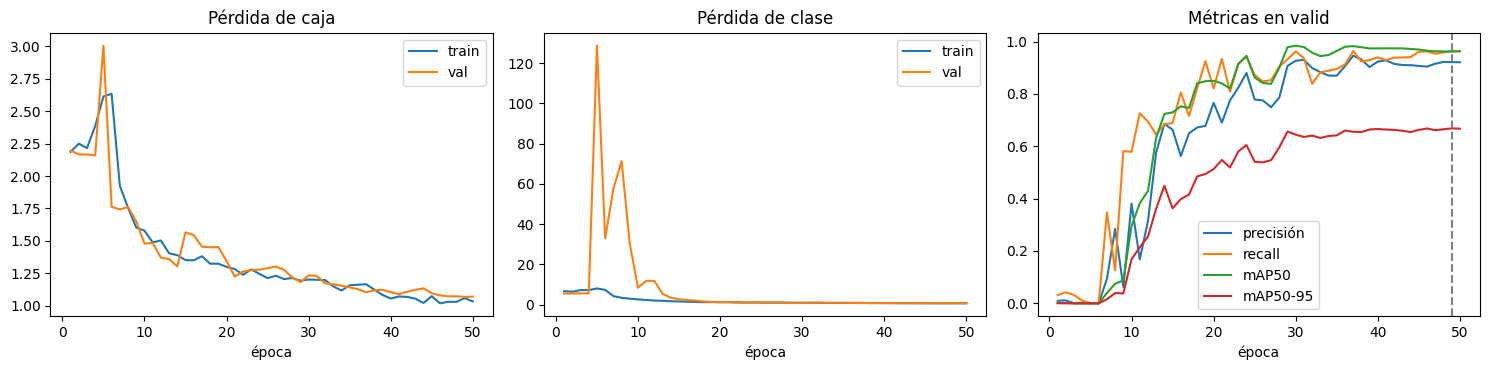

Si la pérdida de valid sube mientras la de train baja, hay sobreajuste; best.pt ya es el de la mejor época.


In [10]:
res = pd.read_csv(RUN_DIR / "results.csv"); res.columns = [c.strip() for c in res.columns]
mejor_ep = int(res.loc[res["metrics/mAP50-95(B)"].idxmax(), "epoch"])
print(f"Épocas entrenadas: {len(res)} de {EPOCAS} · mejor mAP50-95 en valid: época {mejor_ep} ({res['metrics/mAP50-95(B)'].max():.3f})")

fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for k in ["train/box_loss", "val/box_loss"]: axs[0].plot(res["epoch"], res[k], label=k.split("/")[0])
axs[0].set_title("Pérdida de caja"); axs[0].legend()
for k in ["train/cls_loss", "val/cls_loss"]: axs[1].plot(res["epoch"], res[k], label=k.split("/")[0])
axs[1].set_title("Pérdida de clase"); axs[1].legend()
for k, lab in [("metrics/precision(B)", "precisión"), ("metrics/recall(B)", "recall"), ("metrics/mAP50(B)", "mAP50"), ("metrics/mAP50-95(B)", "mAP50-95")]:
    axs[2].plot(res["epoch"], res[k], label=lab)
axs[2].axvline(mejor_ep, ls="--", color="gray"); axs[2].set_title("Métricas en valid"); axs[2].legend()
for a in axs: a.set_xlabel("época")
plt.tight_layout(); plt.savefig(RUN_DIR / "curvas_entrenamiento.png", dpi=150); plt.show()
if len(res) < EPOCAS: print(f"La parada temprana detuvo el entrenamiento en la época {len(res)} (paciencia={PACIENCIA}).")
print("Si la pérdida de valid sube mientras la de train baja, hay sobreajuste; best.pt ya es el de la mejor época.")

## 5. Métricas estándar de detección
`best.pt` se eligió con el *fitness* de valid (mezcla de mAP50 y mAP50-95), así que **las de valid están algo infladas**; si hay test, esas son las que se reportan. Precisión y recall corresponden al umbral que maximiza F1.

In [11]:
best = YOLO(RUN_DIR / "weights" / "best.pt")
SPLITS_EVAL = ["val"] + (["test"] if TIENE_TEST else [])

def evaluar_estandar(split):
    m = best.val(data=str(YAML), split=split, imgsz=IMGSZ, batch=BATCH, conf=0.001, iou=IOU_NMS_EVAL,
                 plots=True, project=str(RUNS), name=f"{RUN_NAME}_eval_{split}", exist_ok=True, verbose=False)
    b = m.box; p, r = float(b.mp), float(b.mr)
    glob = dict(particion=split, cortes=len(IMGS[split]), precision=p, recall=r,
                F1=(2 * p * r / (p + r)) if (p + r) else 0.0, mAP50=float(b.map50), mAP50_95=float(b.map))
    por_clase = [dict(particion=split, nivel=m.names[int(c)], precision=pc, recall=rc, mAP50=ap50, mAP50_95=ap)
                 for i, c in enumerate(b.ap_class_index) for (pc, rc, ap50, ap) in [b.class_result(i)]]
    return glob, por_clase

globales, por_clase = [], []
for s in SPLITS_EVAL:
    g, c = evaluar_estandar(s); globales.append(g); por_clase += c
metricas_estandar = pd.DataFrame(globales).round(4); metricas_por_clase = pd.DataFrame(por_clase).round(4)
display(metricas_estandar); display(metricas_por_clase)

Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1479.1±423.7 MB/s, size: 30.9 KB)
val: Scanning /content/dataset_rf/valid/labels.cache... 20 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 20/20 5.6Mit/s 0.0s
val: /content/dataset_rf/valid/images/T2_TSE_SAG__0001_008_png.rf.96e2013f085301bbed2ce9f2925811ee.jpg: ignoring corrupt image/label: labels mix segment and detection rows
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 2.5it/s 0.8s
                   all         19         95      0.922      0.964      0.962      0.663
Speed: 6.2ms preprocess, 13.8ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/runs/detector_discos_v1_s42_20261031_0332_eval_val
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 1

,particion,cortes,precision,recall,F1,mAP50,mAP50_95
0,val,20,0.9219,0.9641,0.9425,0.9621,0.6634
1,test,10,0.9825,0.9940,0.9882,0.9950,0.6905


,particion,nivel,precision,recall,mAP50,mAP50_95
0,val,L1-L2,0.8385,0.8204,0.8608,0.6364
1,val,L2-L3,0.8578,1.0000,0.9648,0.6883
2,val,L3-L4,0.9991,1.0000,0.9950,0.6591
3,val,L4-L5,0.9783,1.0000,0.9950,0.6234
4,val,L5-S1,0.9357,1.0000,0.9950,0.7099
5,test,L1-L2,1.0000,0.9701,0.9950,0.7396
6,test,L2-L3,0.9972,1.0000,0.9950,0.7201
7,test,L3-L4,0.9737,1.0000,0.9950,0.6828
8,test,L4-L5,0.9664,1.0000,0.9950,0.6418
9,test,L5-S1,0.9750,1.0000,0.9950,0.6680


## 6. Métrica práctica: ¿salen los 5 niveles, en orden?
Para cada corte se toma, **por nivel**, la caja de mayor confianza (NMS 0.4 y confianza ≥ umbral, como en `autocrop_rois.py`). Un corte es **utilizable** si:
- aparecen los 5 niveles,
- el centro vertical crece de L1-L2 a L5-S1 (orden anatómico),
- las cajas consecutivas no se solapan más de IoU 0.5 (la misma regla que se usó para excluir cortes al construir el dataset).

También se mide el **IoU** de cada caja con su etiqueta. El umbral se elige con valid; test se mira una vez.

In [12]:
def iou_cajas(a, b):
    w = max(0.0, min(a[2], b[2]) - max(a[0], b[0])); h = max(0.0, min(a[3], b[3]) - max(a[1], b[1])); i = w * h
    u = (a[2]-a[0]) * (a[3]-a[1]) + (b[2]-b[0]) * (b[3]-b[1]) - i
    return i / u if u else 0.0

def predecir_cortes(split, conf_min=0.05):
    """Por corte: mejor caja por nivel (con su confianza), sin filtrar por umbral todavía."""
    out = []
    rutas = IMGS[split]
    for i in range(0, len(rutas), 16):
        lote = rutas[i:i+16]
        for p, r in zip(lote, best.predict([str(x) for x in lote], imgsz=IMGSZ, conf=conf_min, iou=IOU_NMS_USO, verbose=False)):
            h, w = r.orig_shape; gt = leer_etiquetas(p, w, h); mejor = {}
            for b in r.boxes:
                c = int(b.cls[0]); cf = float(b.conf[0])
                if c not in mejor or cf > mejor[c][0]: mejor[c] = (cf, tuple(map(float, b.xyxy[0].tolist())))
            out.append(dict(archivo=p.name, gt=gt, pred=mejor))
    return out

def evaluar_umbral(cortes, umbral):
    filas = []
    for c in cortes:
        det = {k: v for k, v in c["pred"].items() if v[0] >= umbral}
        niveles_ok = [k for k in range(5) if k in det]
        ious = {k: iou_cajas(det[k][1], c["gt"][k]) for k in niveles_ok if k in c["gt"]}
        yc = [(det[k][1][1] + det[k][1][3]) / 2 for k in niveles_ok]
        orden = all(a < b for a, b in zip(yc, yc[1:]))
        solapa = any(iou_cajas(det[k][1], det[k + 1][1]) > 0.5 for k in range(4) if k in det and k + 1 in det)
        filas.append(dict(archivo=c["archivo"], niveles_detectados=len(niveles_ok), orden_ok=orden, sin_solape=not solapa,
                          utilizable=(len(niveles_ok) == 5 and orden and not solapa),
                          iou_medio=np.mean(list(ious.values())) if ious else 0.0,
                          iou_min=min(ious.values()) if ious else 0.0,
                          **{f"iou_{NIVELES[k]}": ious.get(k, 0.0) for k in range(5)}))
    return pd.DataFrame(filas)

pred_val = predecir_cortes("val")
filas = []
for u in [0.10, 0.20, 0.30, 0.35, 0.40, 0.50, 0.60, 0.70]:
    d = evaluar_umbral(pred_val, u)
    filas.append(dict(umbral=u, cortes=len(d), utilizables=d.utilizable.mean(), cinco_niveles=(d.niveles_detectados == 5).mean(),
                      niveles_medios=d.niveles_detectados.mean(), IoU_medio=d.iou_medio.mean(), IoU_min_medio=d.iou_min.mean(),
                      IoU_ge_050=(d.iou_min >= 0.5).mean()))
barrido = pd.DataFrame(filas).round(3)
print("Barrido del umbral SOLO sobre valid (aquí se elige CONF_USO):"); display(barrido)

Barrido del umbral SOLO sobre valid (aquí se elige CONF_USO):


,umbral,cortes,utilizables,cinco_niveles,niveles_medios,IoU_medio,IoU_min_medio,IoU_ge_050
0,0.10,20,1.00,1.00,5.00,0.819,0.649,0.85
1,0.20,20,1.00,1.00,5.00,0.819,0.649,0.85
2,0.30,20,0.95,0.95,4.95,0.819,0.649,0.85
3,0.35,20,0.95,0.95,4.95,0.819,0.649,0.85
4,0.40,20,0.95,0.95,4.95,0.819,0.649,0.85
5,0.50,20,0.90,0.90,4.90,0.818,0.649,0.85
6,0.60,20,0.65,0.65,4.65,0.813,0.649,0.85
7,0.70,20,0.30,0.30,3.95,0.809,0.663,0.85


**Cómo elegir el umbral:** busca el valor con más cortes `utilizables`. Uno alto deja niveles sin detectar; uno bajo acepta cajas dudosas. El pipeline actual usa 0.35. Si cambias `CONF_USO`, vuelve a ejecutar desde la celda siguiente. **No lo ajustes mirando el test.**

In [13]:
detalle = {"val": evaluar_umbral(pred_val, CONF_USO)}
if TIENE_TEST:
    pred_test = predecir_cortes("test"); detalle["test"] = evaluar_umbral(pred_test, CONF_USO)

filas = []
for s, d in detalle.items():
    filas.append(dict(particion=s, umbral=CONF_USO, cortes=len(d), utilizables=d.utilizable.mean(),
                      niveles_medios=d.niveles_detectados.mean(), IoU_medio=d.iou_medio.mean(), IoU_min_medio=d.iou_min.mean(),
                      **{f"IoU_{n}": d[f"iou_{n}"].mean() for n in NIVELES}))
tabla_practica = pd.DataFrame(filas).round(3)
print(f"Con CONF_USO={CONF_USO} y NMS={IOU_NMS_USO}:"); display(tabla_practica.T)
for s, d in detalle.items():
    print(f"{s}: n={len(d)}; un corte mueve {100/len(d):.1f} puntos el porcentaje de utilizables.")
    malos = d[~d.utilizable]
    if len(malos): print(f"  Cortes NO utilizables en {s}:"); display(malos[["archivo", "niveles_detectados", "orden_ok", "sin_solape", "iou_min"]].round(3))

Con CONF_USO=0.35 y NMS=0.4:


,0,1
particion,val,test
umbral,0.35,0.35
cortes,20,10
utilizables,0.95,1.0
niveles_medios,4.95,5.0
IoU_medio,0.819,0.843
IoU_min_medio,0.649,0.751
IoU_L1-L2,0.74,0.856
IoU_L2-L3,0.858,0.862
IoU_L3-L4,0.799,0.832


val: n=20; un corte mueve 5.0 puntos el porcentaje de utilizables.
  Cortes NO utilizables en val:


,archivo,niveles_detectados,orden_ok,sin_solape,iou_min
0,T2_TSE_SAG__0001_007_png.rf.bcd7295a82265ed47c...,4,True,True,0.846


test: n=10; un corte mueve 10.0 puntos el porcentaje de utilizables.


## 7. Ejemplos: etiqueta (verde), predicción (rojo) y ROI de 128×128

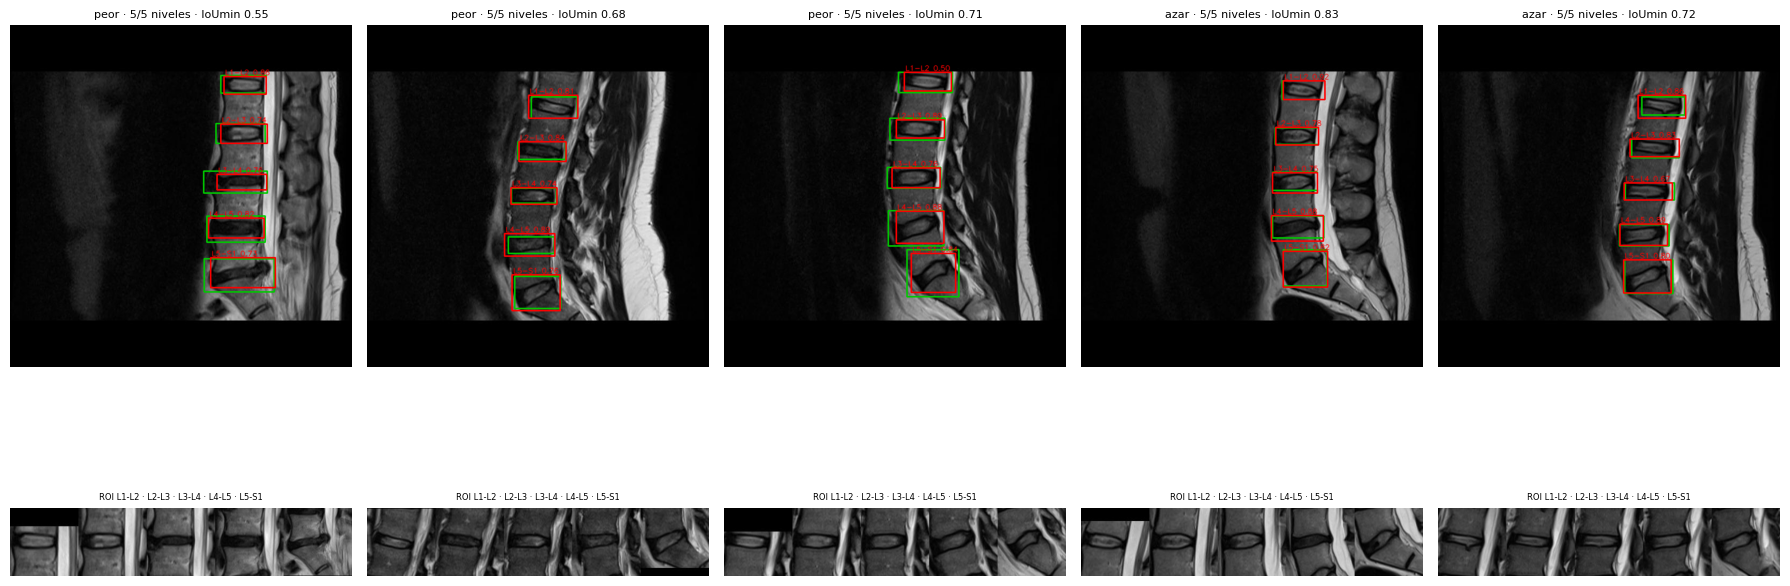

Las 3 primeras columnas son los peores cortes de test; las demás, al azar.


In [14]:
def expandir_cuadrado(img, x1, y1, x2, y2):
    """Misma expansión que autocrop_rois.py: márgenes posterior/anterior/vertical y cuadrado."""
    h, w = img.shape[:2]; bw, bh = x2 - x1, y2 - y1
    nx1, nx2 = x1 - MARGIN_ANT * bw, x2 + MARGIN_POST * bw
    ny1, ny2 = y1 - MARGIN_VERT * bh, y2 + MARGIN_VERT * bh
    cx, cy = (nx1 + nx2) / 2, (ny1 + ny2) / 2; lado = max(nx2 - nx1, ny2 - ny1)
    sx1, sy1, sx2, sy2 = [int(round(v)) for v in (cx - lado/2, cy - lado/2, cx + lado/2, cy + lado/2)]
    pad = max(0, -sy1, sy2 - h, -sx1, sx2 - w)
    if pad > 0:
        img = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=int(np.median(img)))
        sx1 += pad; sx2 += pad; sy1 += pad; sy2 += pad
    return img[sy1:sy2, sx1:sx2]

def rois_de(img_gray, modelo, conf=None):
    """Lo que hará el pipeline: devuelve {nivel: parche 128x128} para los niveles detectados."""
    conf = CONF_USO if conf is None else conf
    r = modelo.predict(cv2.cvtColor(img_gray, cv2.COLOR_GRAY2BGR), imgsz=IMGSZ, conf=conf, iou=IOU_NMS_USO, verbose=False)[0]
    mejor = {}
    for b in r.boxes:
        c = int(b.cls[0]); cf = float(b.conf[0])
        if c not in mejor or cf > mejor[c][0]: mejor[c] = (cf, *map(float, b.xyxy[0].tolist()))
    out = {}
    for c, (cf, x1, y1, x2, y2) in mejor.items():
        parche = expandir_cuadrado(img_gray, x1, y1, x2, y2)
        if parche.size:
            interp = cv2.INTER_AREA if parche.shape[0] > PATCH else cv2.INTER_CUBIC
            out[NIVELES[c]] = cv2.resize(parche, (PATCH, PATCH), interpolation=interp)
    return out

split_ej = "test" if TIENE_TEST else "val"
d_ej = detalle[split_ej]; pred_ej = pred_test if TIENE_TEST else pred_val
por_nombre = {c["archivo"]: c for c in pred_ej}; rutas = {p.name: p for p in IMGS[split_ej]}
orden = d_ej.sort_values(["utilizable", "iou_min"]).archivo.tolist()
elegidos = orden[:3] + random.Random(SEMILLA).sample(orden[3:], min(2, max(0, len(orden) - 3)))

fig, axs = plt.subplots(2, len(elegidos), figsize=(3.6 * len(elegidos), 8.4), squeeze=False)
for j, a in enumerate(elegidos):
    p = rutas[a]; g = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE); im = cv2.cvtColor(g, cv2.COLOR_GRAY2BGR)
    c = por_nombre[a]; im = dibujar(im, [c["gt"][k] for k in sorted(c["gt"])], (0, 200, 0))
    det = {k: v for k, v in c["pred"].items() if v[0] >= CONF_USO}
    im = dibujar(im, [det[k][1] for k in sorted(det)], (0, 0, 255), [f"{NIVELES[k]} {det[k][0]:.2f}" for k in sorted(det)])
    fila = d_ej[d_ej.archivo == a].iloc[0]
    axs[0, j].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axs[0, j].axis("off")
    axs[0, j].set_title(f"{'peor' if j < 3 else 'azar'} · {int(fila.niveles_detectados)}/5 niveles · IoUmin {fila.iou_min:.2f}", fontsize=8)
    rois = rois_de(g, best)
    tira = np.hstack([rois.get(n, np.zeros((PATCH, PATCH), np.uint8)) for n in NIVELES])
    axs[1, j].imshow(tira, cmap="gray", vmin=0, vmax=255); axs[1, j].axis("off"); axs[1, j].set_title("ROI " + " · ".join(NIVELES), fontsize=6)
plt.tight_layout(); plt.savefig(RUN_DIR / "ejemplos.png", dpi=140); plt.show()
print(f"Las 3 primeras columnas son los peores cortes de {split_ej}; las demás, al azar.")

In [ ]:
# Opcional: un paciente nuevo (PNG en CARPETA_PRUEBAS). Si la carpeta no existe, se omite.
pruebas = sorted(Path(CARPETA_PRUEBAS).glob("*.png")) if Path(CARPETA_PRUEBAS).is_dir() else []
if pruebas:
    fig, axs = plt.subplots(1, len(pruebas), figsize=(4 * len(pruebas), 5), squeeze=False)
    for ax, f in zip(axs[0], pruebas):
        r = best.predict(str(f), imgsz=IMGSZ, conf=CONF_USO, iou=IOU_NMS_USO, verbose=False)[0]
        ax.imshow(cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)); ax.set_title(f"{f.name} · {len(r.boxes)} cajas", fontsize=8); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Sin carpeta de pruebas; se omite.")

## 8. Guardar en Google Drive
Pesos (incluida una copia como `best_disc_detector.pt`, el nombre que usa `autocrop_rois.py`), curvas, gráficas de Ultralytics, tablas CSV y un JSON con la configuración exacta.

In [15]:
(DEST / "weights").mkdir(parents=True, exist_ok=True)
shutil.copy(RUN_DIR / "weights" / "best.pt", DEST / "weights" / "best.pt")
shutil.copy(RUN_DIR / "weights" / "best.pt", DEST / "weights" / "best_disc_detector.pt")
if (RUN_DIR / "weights" / "last.pt").exists(): shutil.copy(RUN_DIR / "weights" / "last.pt", DEST / "weights" / "last.pt")
for f in RUN_DIR.glob("*"):
    if f.is_file(): shutil.copy(f, DEST / f.name)
for split in SPLITS_EVAL:
    d = RUNS / f"{RUN_NAME}_eval_{split}"
    if d.exists(): shutil.copytree(d, DEST / f"eval_{split}", dirs_exist_ok=True)
shutil.copy(YAML, DEST / "data.yaml")

metricas_estandar.to_csv(DEST / "metricas_estandar.csv", index=False)
metricas_por_clase.to_csv(DEST / "metricas_por_nivel.csv", index=False)
barrido.to_csv(DEST / "barrido_umbral_valid.csv", index=False)
tabla_practica.to_csv(DEST / "metricas_practicas.csv", index=False)
for s, d in detalle.items(): d.assign(particion=s).to_csv(DEST / f"detalle_por_corte_{s}.csv", index=False)
resumen_dataset.to_csv(DEST / "resumen_dataset.csv", index=False)

if EXPORTAR_ONNX:
    try: shutil.copy(best.export(format="onnx", imgsz=IMGSZ), DEST / "weights" / "best.onnx")
    except Exception as e: print("(aviso) no se pudo exportar a ONNX:", e)

meta = dict(
    fecha=datetime.datetime.now().isoformat(timespec="seconds"),
    roboflow=dict(workspace=RF_WORKSPACE, proyecto=RF_PROJECT, version=RF_VERSION, formato="yolov8"),
    tarea="detect (cajas normales, sin OBB)", modelo_base=MODELO_BASE, clases=NIVELES,
    hiperparametros=dict(epocas=EPOCAS, paciencia=PACIENCIA, batch=BATCH, imgsz=IMGSZ, optimizador=OPTIMIZADOR, lr0=LR0, lrf=LRF,
                         weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS, cos_lr=COS_LR, close_mosaic=CLOSE_MOSAIC,
                         semilla=SEMILLA, aumento=AUG),
    epocas_entrenadas=int(len(res)), mejor_epoca_valid=mejor_ep,
    cortes={s: len(v) for s, v in IMGS.items()}, tiene_test=TIENE_TEST,
    metricas_estandar=metricas_estandar.to_dict(orient="records"),
    uso=dict(conf_uso=CONF_USO, iou_nms_uso=IOU_NMS_USO, margenes=dict(post=MARGIN_POST, ant=MARGIN_ANT, vert=MARGIN_VERT), parche=PATCH),
    metricas_practicas=tabla_practica.to_dict(orient="records"),
    versiones=dict(python=platform.python_version(), torch=torch.__version__, ultralytics=ultralytics.__version__),
    advertencias=["dataset pequeño: un corte mueve varios puntos los porcentajes",
                  "una sola corrida, una sola semilla",
                  "best.pt elegido por fitness en valid: las métricas de valid están algo infladas" + ("" if TIENE_TEST else " y NO hay test: no hay estimación independiente"),
                  "el umbral de uso se eligió con valid; el test (si existe) se miró una vez",
                  "si varios cortes de un paciente caen en particiones distintas, las métricas salen infladas (ver sección 2)"],
)
(DEST / "metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print("Guardado en Drive:", DEST)
print("Pesos para el pipeline:", DEST / "weights" / "best_disc_detector.pt")

Guardado en Drive: /content/drive/MyDrive/VisionArtificial/detector_discos/detector_discos_v1_s42_20261031_0332
Pesos para el pipeline: /content/drive/MyDrive/VisionArtificial/detector_discos/detector_discos_v1_s42_20261031_0332/weights/best_disc_detector.pt
